In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = sns.load_dataset('iris')
df.columns


Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [3]:
df=df[df["species"].isin(["setosa", "versicolor"])]

df["species"] = df["species"].map({
    "setosa": 0,
    "versicolor": 1
})

In [4]:
X=df.drop(columns="species")
y=df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
df


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
95,5.7,3.0,4.2,1.2,1
96,5.7,2.9,4.2,1.3,1
97,6.2,2.9,4.3,1.3,1
98,5.1,2.5,3.0,1.1,1


In [6]:
X_train = X_train.T
y_train = y_train.to_numpy().reshape(1, -1)
X_test = X_test.T
y_test = y_test.to_numpy().reshape(1,-1)

In [7]:
print("Shape of X_train : ", X_train.shape)
print("Shape of Y_train : ", y_train.shape)
print("Shape of X_test : ", X_test.shape)
print("Shape of Y_test : ", y_test.shape)

Shape of X_train :  (4, 80)
Shape of Y_train :  (1, 80)
Shape of X_test :  (4, 20)
Shape of Y_test :  (1, 20)


In [8]:
def sigmoid(Z):
    return 1/(1 + np.exp(-Z))

In [9]:
def logistic_regession(X,y,iterations,learning_rate) :

    m = X_train.shape[1]
    n = X_train.shape[0]
    W=np.zeros((n,1))
    b=0

    cost_list=[]
    for i in range(iterations):

        # finding value of z(score)
        Z=np.dot(W.T,X) + b

        # finding probablity
        S=sigmoid(Z)

        # cost function
        cost = -(1/m)*np.sum( y*np.log(S) + (1-y)*np.log(1-S))

        # Gradient Descent
        dW = (1/m)*np.dot(S-y, X.T)
        dB = (1/m)*np.sum(S - y)
            
        W = W - learning_rate*dW.T
        b = b - learning_rate*dB

        cost_list.append(cost)

        if(i%(iterations/10) == 0):
            print("cost after ", i, "iteration is : ", cost)

    return W,b,cost_list



In [10]:
iterations = 10000
learning_rate = 0.0015
W, b, cost_list = logistic_regession(X_train, y_train, learning_rate = learning_rate, iterations = iterations)

cost after  0 iteration is :  0.6931471805599454
cost after  1000 iteration is :  0.3226608781762881
cost after  2000 iteration is :  0.2005719913545388
cost after  3000 iteration is :  0.14379689840314783
cost after  4000 iteration is :  0.11174869200601521
cost after  5000 iteration is :  0.09133863078801135
cost after  6000 iteration is :  0.07725338309660089
cost after  7000 iteration is :  0.06696502466409453
cost after  8000 iteration is :  0.05912701974093018
cost after  9000 iteration is :  0.05295939528489764


In [11]:
def accuracy(X, Y, W, B):
    
    Z = np.dot(W.T, X) + B
    S = sigmoid(Z)
    
    S = S > 0.5
    
    S = np.array(S, dtype = 'int64')
    
    acc = (1 - np.sum(np.absolute(S - Y))/Y.shape[1])*100
    
    print("Accuracy of the model is : ", round(acc, 2), "%")

In [12]:
accuracy(X_test,y_test,W,b)

Accuracy of the model is :  100.0 %


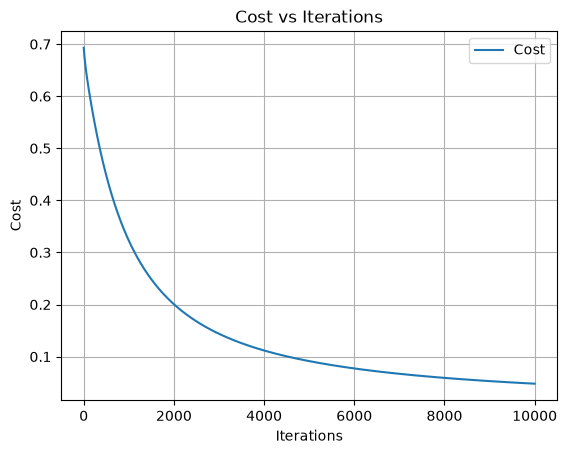

In [13]:
# gradient curve
# X-axis — Iterations: How many times the model has updated its weights (W) and bias (b).
# Y-axis — Cost: How badly the model's predicted probabilities differ from the actual labels.

sns.lineplot(x=np.arange(iterations), y=cost_list,label="Cost")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost vs Iterations")
plt.legend()
plt.grid(True)
plt.show()